In [ ]:
!pip install -q fastapi uvicorn python-multipart kaggle scikit-learn

In [ ]:
import tensorflow as tf

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
!pip install -q kaggle

In [ ]:
import os
from getpass import getpass
from pathlib import Path

token = getpass("Paste your NEW Kaggle API token here: ")

os.environ["KAGGLE_API_TOKEN"] = token

token_dir = Path.home() / ".kaggle"
token_dir.mkdir(parents=True, exist_ok=True)

token_file = token_dir / "access_token"
token_file.write_text(token)
token_file.chmod(0o600)

del token

print("Kaggle token configured.")

Paste your NEW Kaggle API token here: ··········
Kaggle token configured.


In [ ]:
!kaggle competitions list

ref                                                                           deadline             category         reward  teamCount  userHasEntered  
----------------------------------------------------------------------------  -------------------  --------  -------------  ---------  --------------  
https://www.kaggle.com/competitions/passenger-screening-algorithm-challenge   2017-12-15 23:59:00  Featured  1,500,000 Usd        518           False  
https://www.kaggle.com/competitions/zillow-prize-1                            2018-01-10 15:59:00  Featured  1,200,000 Usd       3770           False  
https://www.kaggle.com/competitions/data-science-bowl-2017                    2017-04-12 23:59:00  Featured  1,000,000 Usd       1972           False  
https://www.kaggle.com/competitions/vesuvius-challenge-ink-detection          2023-06-14 23:59:00  Featured  1,000,000 Usd       1249           False  
https://www.kaggle.com/competitions/arc-prize-2026-arc-agi-3                  2026-11-02

In [ ]:
!kaggle datasets download -d asdasdasasdas/garbage-classification -p /content --unzip

Dataset URL: https://www.kaggle.com/datasets/asdasdasasdas/garbage-classification
License(s): copyright-authors
100% 82.0M/82.0M [00:05<00:00, 15.5MB/s]



In [ ]:
import os

print(os.listdir("/content"))

['.config', 'garbage classification', 'one-indexed-files.txt', 'one-indexed-files-notrash_train.txt', 'one-indexed-files-notrash_val.txt', 'one-indexed-files-notrash_test.txt', 'Garbage classification', 'zero-indexed-files.txt', 'sample_data']


In [ ]:
import os

for root, dirs, files in os.walk("/content"):
    dirs[:] = [d for d in dirs if d not in [".config", "sample_data"]]
    level = root.replace("/content", "").count(os.sep)
    if level <= 3:
        print("  " * level + os.path.basename(root) + "/")
        for file in files[:5]:
            print("  " * (level + 1) + file)

content/
  one-indexed-files.txt
  one-indexed-files-notrash_train.txt
  one-indexed-files-notrash_val.txt
  one-indexed-files-notrash_test.txt
  zero-indexed-files.txt
  garbage classification/
    Garbage classification/
      trash/
        trash102.jpg
        trash89.jpg
        trash87.jpg
        trash135.jpg
        trash6.jpg
      glass/
        glass294.jpg
        glass130.jpg
        glass90.jpg
        glass214.jpg
        glass282.jpg
      cardboard/
        cardboard371.jpg
        cardboard381.jpg
        cardboard120.jpg
        cardboard16.jpg
        cardboard134.jpg
      plastic/
        plastic358.jpg
        plastic356.jpg
        plastic30.jpg
        plastic170.jpg
        plastic298.jpg
      metal/
        metal252.jpg
        metal38.jpg
        metal44.jpg
        metal140.jpg
        metal230.jpg
      paper/
        paper273.jpg
        paper103.jpg
        paper326.jpg
        paper390.jpg
        paper358.jpg
  Garbage classification/
    Garbage clas

In [ ]:
import os

for folder in [
    "/content/Garbage classification",
    "/content/garbage classification"
]:
    if os.path.isdir(folder):
        print(f"\nFolder: {folder}")
        print(os.listdir(folder))


Folder: /content/Garbage classification
['Garbage classification']

Folder: /content/garbage classification
['Garbage classification']


In [ ]:
import os

base_candidates = [
    "/content/Garbage classification",
    "/content/garbage classification"
]

for base in base_candidates:
    if os.path.isdir(base):
        print(f"\nChecking: {base}")
        for name in os.listdir(base):
            path = os.path.join(base, name)
            if os.path.isdir(path):
                count = sum(
                    1 for f in os.listdir(path)
                    if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp", ".webp"))
                )
                print(f"{name}: {count} images")


Checking: /content/Garbage classification
Garbage classification: 0 images

Checking: /content/garbage classification
Garbage classification: 0 images


In [ ]:
import os

for root, dirs, files in os.walk("/content/Garbage classification"):
    level = root.replace("/content/Garbage classification", "").count(os.sep)
    print("  " * level + os.path.basename(root) + "/")

    for f in files[:3]:
        print("  " * (level + 1) + f)

print("\n========== SECOND FOLDER ==========\n")

for root, dirs, files in os.walk("/content/garbage classification"):
    level = root.replace("/content/garbage classification", "").count(os.sep)
    print("  " * level + os.path.basename(root) + "/")

    for f in files[:3]:
        print("  " * (level + 1) + f)

Garbage classification/
  Garbage classification/
    trash/
      trash102.jpg
      trash89.jpg
      trash87.jpg
    glass/
      glass294.jpg
      glass130.jpg
      glass90.jpg
    cardboard/
      cardboard371.jpg
      cardboard381.jpg
      cardboard120.jpg
    plastic/
      plastic358.jpg
      plastic356.jpg
      plastic30.jpg
    metal/
      metal252.jpg
      metal38.jpg
      metal44.jpg
    paper/
      paper273.jpg
      paper103.jpg
      paper326.jpg

========== SECOND FOLDER ==========

garbage classification/
  Garbage classification/
    trash/
      trash102.jpg
      trash89.jpg
      trash87.jpg
    glass/
      glass294.jpg
      glass130.jpg
      glass90.jpg
    cardboard/
      cardboard371.jpg
      cardboard381.jpg
      cardboard120.jpg
    plastic/
      plastic358.jpg
      plastic356.jpg
      plastic30.jpg
    metal/
      metal252.jpg
      metal38.jpg
      metal44.jpg
    paper/
      paper273.jpg
      paper103.jpg
      paper326.jpg


In [ ]:
import os

image_extensions = (".jpg", ".jpeg", ".png", ".bmp", ".webp")
total_images = 0

for root, dirs, files in os.walk("/content"):
    dirs[:] = [d for d in dirs if d not in [".config", "sample_data"]]

    images = [f for f in files if f.lower().endswith(image_extensions)]

    if images:
        print(f"\nFolder: {root}")
        print(f"Image count: {len(images)}")
        print("Examples:", images[:3])
        total_images += len(images)

print("\nTotal images found:", total_images)


Folder: /content/garbage classification/Garbage classification/trash
Image count: 137
Examples: ['trash102.jpg', 'trash89.jpg', 'trash87.jpg']

Folder: /content/garbage classification/Garbage classification/glass
Image count: 501
Examples: ['glass294.jpg', 'glass130.jpg', 'glass90.jpg']

Folder: /content/garbage classification/Garbage classification/cardboard
Image count: 403
Examples: ['cardboard371.jpg', 'cardboard381.jpg', 'cardboard120.jpg']

Folder: /content/garbage classification/Garbage classification/plastic
Image count: 482
Examples: ['plastic358.jpg', 'plastic356.jpg', 'plastic30.jpg']

Folder: /content/garbage classification/Garbage classification/metal
Image count: 410
Examples: ['metal252.jpg', 'metal38.jpg', 'metal44.jpg']

Folder: /content/garbage classification/Garbage classification/paper
Image count: 594
Examples: ['paper273.jpg', 'paper103.jpg', 'paper326.jpg']

Folder: /content/Garbage classification/Garbage classification/trash
Image count: 137
Examples: ['trash10

In [ ]:
import os

DATA_DIR = "/content/Garbage classification/Garbage classification"

CLASS_NAMES = [
    "cardboard",
    "glass",
    "metal",
    "paper",
    "plastic",
    "trash"
]

for class_name in CLASS_NAMES:
    folder = os.path.join(DATA_DIR, class_name)
    images = [
        f for f in os.listdir(folder)
        if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp", ".webp"))
    ]
    print(f"{class_name}: {len(images)} images")

cardboard: 403 images
glass: 501 images
metal: 410 images
paper: 594 images
plastic: 482 images
trash: 137 images


In [ ]:
import os
from sklearn.model_selection import train_test_split

all_paths = []
all_labels = []

for label, class_name in enumerate(CLASS_NAMES):
    folder = os.path.join(DATA_DIR, class_name)

    for filename in os.listdir(folder):
        if filename.lower().endswith((".jpg", ".jpeg", ".png", ".bmp", ".webp")):
            all_paths.append(os.path.join(folder, filename))
            all_labels.append(label)

# 70% train, 30% temporary
train_paths, temp_paths, train_labels, temp_labels = train_test_split(
    all_paths,
    all_labels,
    test_size=0.30,
    random_state=42,
    stratify=all_labels
)

# Split temporary data equally into validation and test
val_paths, test_paths, val_labels, test_labels = train_test_split(
    temp_paths,
    temp_labels,
    test_size=0.50,
    random_state=42,
    stratify=temp_labels
)

print("Total images:", len(all_paths))
print("Training images:", len(train_paths))
print("Validation images:", len(val_paths))
print("Testing images:", len(test_paths))
print("Classes:", CLASS_NAMES)

Total images: 2527
Training images: 1768
Validation images: 379
Testing images: 380
Classes: ['cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']


In [ ]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

def load_image(path, label):
    image = tf.io.read_file(path)
    image = tf.io.decode_image(
        image,
        channels=3,
        expand_animations=False
    )
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, IMG_SIZE)
    image = preprocess_input(image)
    return image, tf.cast(label, tf.int32)

def make_dataset(paths, labels, training=False):
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))

    if training:
        ds = ds.shuffle(
            buffer_size=len(paths),
            seed=42,
            reshuffle_each_iteration=True
        )

    ds = ds.map(load_image, num_parallel_calls=AUTOTUNE)
    ds = ds.batch(BATCH_SIZE)
    return ds.prefetch(AUTOTUNE)

train_ds = make_dataset(train_paths, train_labels, training=True)
val_ds = make_dataset(val_paths, val_labels)
test_ds = make_dataset(test_paths, test_labels)

print("Datasets created successfully!")

Datasets created successfully!


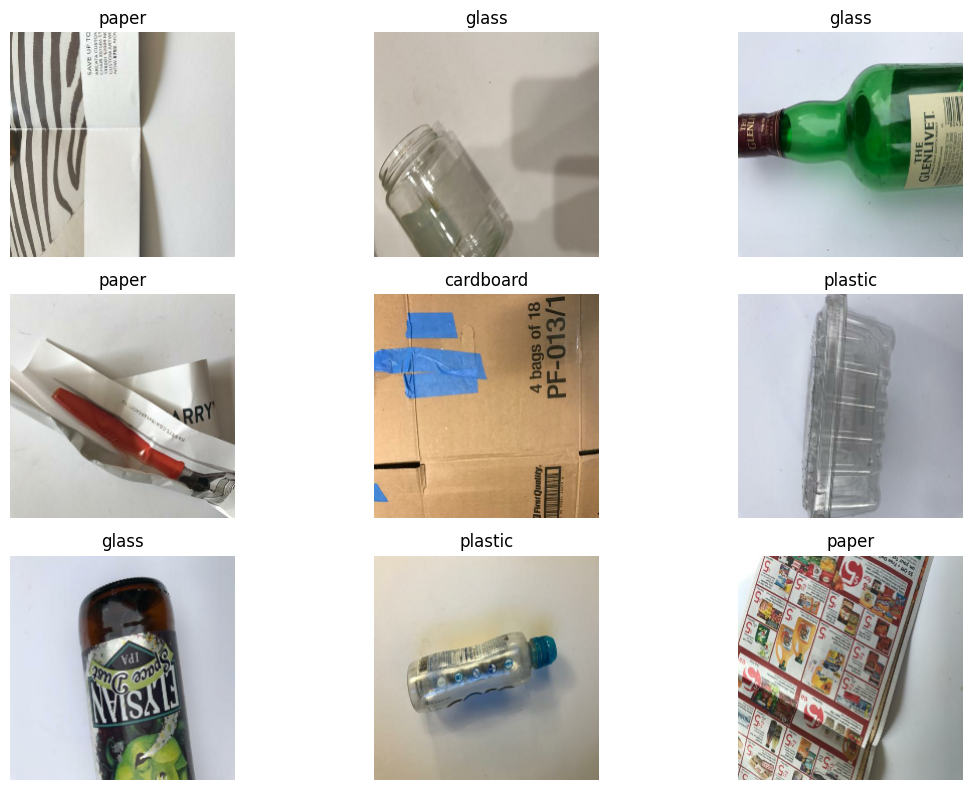

In [ ]:
import matplotlib.pyplot as plt

images, labels = next(iter(train_ds))

plt.figure(figsize=(12, 8))

for i in range(min(9, len(images))):
    plt.subplot(3, 3, i + 1)

    # Reverse MobileNetV2 preprocessing for display
    display_image = (images[i].numpy() + 1.0) / 2.0
    display_image = np.clip(display_image, 0, 1)

    plt.imshow(display_image)
    plt.title(CLASS_NAMES[int(labels[i].numpy())])
    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2

NUM_CLASSES = len(CLASS_NAMES)

base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

# Freeze pretrained layers initially
base_model.trainable = False

inputs = layers.Input(shape=(224, 224, 3))

# Data augmentation for training
x = layers.RandomFlip("horizontal")(inputs)
x = layers.RandomRotation(0.1)(x)
x = layers.RandomZoom(0.1)(x)

# MobileNetV2 feature extraction
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.BatchNormalization()(x)
x = layers.Dropout(0.3)(x)
x = layers.Dense(128, activation="relu")(x)
x = layers.Dropout(0.2)(x)

outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)

model = models.Model(inputs, outputs)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip (RandomFlip)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 224, 224, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 1280)           │         5,120 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,427,846 (9.26 MB)

 Trainable params: 167,302 (653.52 KB)

 Non-trainable params: 2,260,544 (8.62 MB)

In [ ]:
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint,
    ReduceLROnPlateau
)

callbacks = [
    ModelCheckpoint(
        "/content/smartwaste_best.keras",
        monitor="val_accuracy",
        save_best_only=True,
        mode="max",
        verbose=1
    ),
    EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2,
        min_lr=1e-6,
        verbose=1
    )
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=callbacks
)

Epoch 1/15
56/56 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step - accuracy: 0.4846 - loss: 1.4985
Epoch 1: val_accuracy improved from None to 0.77309, saving model to /content/smartwaste_best.keras

Epoch 1: finished saving model to /content/smartwaste_best.keras
56/56 ━━━━━━━━━━━━━━━━━━━━ 18s 133ms/step - accuracy: 0.6193 - loss: 1.1234 - val_accuracy: 0.7731 - val_loss: 0.6179 - learning_rate: 0.0010
Epoch 2/15
55/56 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step - accuracy: 0.7684 - loss: 0.6372
Epoch 2: val_accuracy improved from 0.77309 to 0.82322, saving model to /content/smartwaste_best.keras

Epoch 2: finished saving model to /content/smartwaste_best.keras
56/56 ━━━━━━━━━━━━━━━━━━━━ 5s 91ms/step - accuracy: 0.7760 - loss: 0.6342 - val_accuracy: 0.8232 - val_loss: 0.5136 - learning_rate: 0.0010
Epoch 3/15
55/56 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step - accuracy: 0.7851 - loss: 0.6131
Epoch 3: val_accuracy improved from 0.82322 to 0.82586, saving model to /content/smartwaste_best.keras

Epoch 3: finished saving

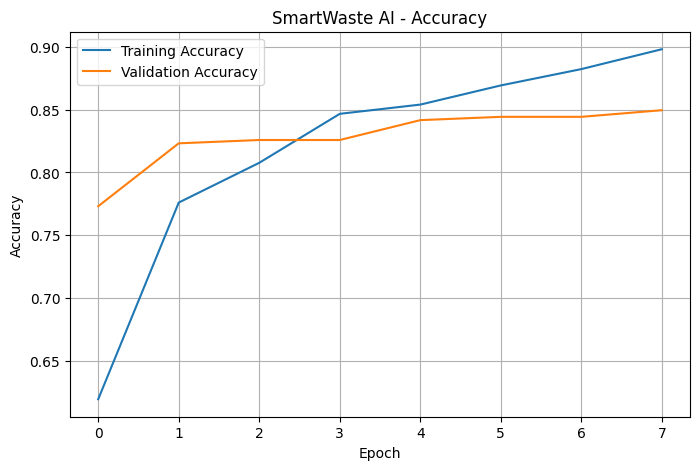

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.title("SmartWaste AI - Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
test_loss, test_accuracy = model.evaluate(test_ds, verbose=1)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

12/12 ━━━━━━━━━━━━━━━━━━━━ 2s 128ms/step - accuracy: 0.8684 - loss: 0.4116
Test Loss: 0.4116
Test Accuracy: 86.84%


In [ ]:
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix

y_true = np.concatenate([
    labels.numpy() for _, labels in test_ds
])

y_prob = model.predict(test_ds)
y_pred = np.argmax(y_prob, axis=1)

print(classification_report(
    y_true,
    y_pred,
    labels=list(range(len(CLASS_NAMES))),
    target_names=CLASS_NAMES,
    zero_division=0
))

12/12 ━━━━━━━━━━━━━━━━━━━━ 5s 230ms/step
              precision    recall  f1-score   support

   cardboard       0.93      0.93      0.93        60
       glass       0.84      0.86      0.85        76
       metal       0.85      0.84      0.85        62
       paper       0.96      0.90      0.93        89
     plastic       0.81      0.86      0.83        73
       trash       0.67      0.70      0.68        20

    accuracy                           0.87       380
   macro avg       0.84      0.85      0.85       380
weighted avg       0.87      0.87      0.87       380



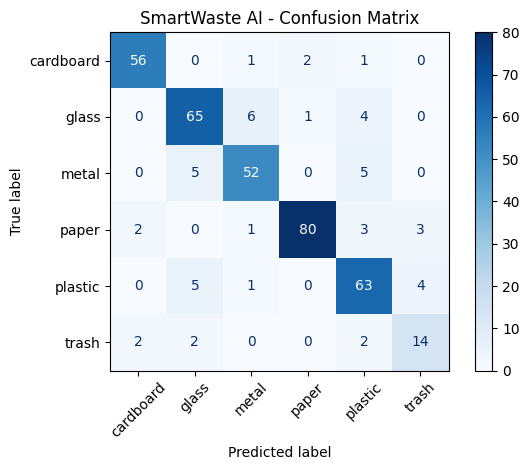

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(len(CLASS_NAMES)))
)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=CLASS_NAMES
)

display.plot(xticks_rotation=45, cmap="Blues")
plt.title("SmartWaste AI - Confusion Matrix")
plt.tight_layout()
plt.show()

In [ ]:
model.save("/content/smartwaste_model.keras")
print("Model saved successfully!")

Model saved successfully!


In [ ]:
!pip install -q fastapi uvicorn python-multipart

In [ ]:
%%writefile /content/app.py

import io
import numpy as np
import tensorflow as tf

from PIL import Image
from fastapi import FastAPI, File, UploadFile, HTTPException
from fastapi.responses import JSONResponse
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

app = FastAPI(
    title="SmartWaste AI API",
    description="AI-powered waste classification using MobileNetV2",
    version="1.0"
)

MODEL_PATH = "/content/smartwaste_model.keras"

CLASS_NAMES = [
    "cardboard",
    "glass",
    "metal",
    "paper",
    "plastic",
    "trash"
]

IMG_SIZE = (224, 224)

model = tf.keras.models.load_model(MODEL_PATH)

@app.get("/")
def home():
    return {
        "message": "SmartWaste AI API is running",
        "categories": CLASS_NAMES
    }

@app.get("/health")
def health():
    return {"status": "healthy", "model_loaded": model is not None}

@app.post("/predict")
async def predict(file: UploadFile = File(...)):
    if file.content_type and not file.content_type.startswith("image/"):
        raise HTTPException(
            status_code=400,
            detail="Please upload an image file."
        )

    try:
        contents = await file.read()
        image = Image.open(io.BytesIO(contents)).convert("RGB")
        image = image.resize(IMG_SIZE)

        image_array = np.array(image, dtype=np.float32)
        image_array = preprocess_input(image_array)
        image_array = np.expand_dims(image_array, axis=0)

        predictions = model.predict(image_array, verbose=0)[0]
        predicted_index = int(np.argmax(predictions))

        return JSONResponse({
            "filename": file.filename,
            "predicted_category": CLASS_NAMES[predicted_index],
            "confidence": round(float(predictions[predicted_index]) * 100, 2),
            "probabilities": {
                CLASS_NAMES[i]: round(float(predictions[i]) * 100, 2)
                for i in range(len(CLASS_NAMES))
            }
        })

    except Exception as e:
        raise HTTPException(
            status_code=400,
            detail=f"Could not process image: {str(e)}"
        )

Writing /content/app.py


In [ ]:
import subprocess
import time
import requests

# Start the server
server = subprocess.Popen(
    [
        "python", "-m", "uvicorn",
        "app:app",
        "--app-dir", "/content",
        "--host", "0.0.0.0",
        "--port", "8000"
    ],
    stdout=open("/content/smartwaste_api.log", "w"),
    stderr=subprocess.STDOUT
)

time.sleep(5)

try:
    response = requests.get("http://127.0.0.1:8000/health")
    print("Status code:", response.status_code)
    print("Response:", response.json())
except Exception as e:
    print("Server did not start correctly:", e)
    print(open("/content/smartwaste_api.log").read()[-4000:])

Server did not start correctly: HTTPConnectionPool(host='127.0.0.1', port=8000): Max retries exceeded with url: /health (Caused by NewConnectionError('<urllib3.connection.HTTPConnection object at 0x7902b147e510>: Failed to establish a new connection: [Errno 111] Connection refused'))



In [ ]:
with open("/content/smartwaste_api.log", "r") as f:
    print(f.read()[-6000:])

W0000 00:00:1791821123.446695    3124 gpu_bfc_allocator.cc:47] Overriding orig_value setting because the TF_FORCE_GPU_ALLOW_GROWTH environment variable is set. Original config value was false.
INFO:     Started server process [3124]
INFO:     Waiting for application startup.
INFO:     Application startup complete.
INFO:     Uvicorn running on http://0.0.0.0:8000 (Press CTRL+C to quit)



In [ ]:
import os

print("Model exists:", os.path.exists("/content/smartwaste_model.keras"))
print("API file exists:", os.path.exists("/content/app.py"))
print("Model file size (MB):",
      round(os.path.getsize("/content/smartwaste_model.keras") / (1024 * 1024), 2)
      if os.path.exists("/content/smartwaste_model.keras") else "Not found")

Model exists: True
API file exists: True
Model file size (MB): 11.12


In [ ]:
import tensorflow as tf

try:
    test_model = tf.keras.models.load_model(
        "/content/smartwaste_model.keras"
    )
    print("SUCCESS: Model loaded correctly!")
    print("Input shape:", test_model.input_shape)
    print("Output shape:", test_model.output_shape)
except Exception as e:
    print("MODEL LOADING ERROR:")
    print(repr(e))

SUCCESS: Model loaded correctly!
Input shape: (None, 224, 224, 3)
Output shape: (None, 6)


In [ ]:
import os

log_path = "/content/smartwaste_api.log"

print("=== API SERVER LOG ===")
if os.path.exists(log_path):
    with open(log_path, "r") as f:
        print(f.read()[-6000:])
else:
    print("Server log file not found.")

print("\n=== REQUIRED FILES ===")
print("API file exists:", os.path.exists("/content/app.py"))
print("Model file exists:", os.path.exists("/content/smartwaste_model.keras"))

=== API SERVER LOG ===
W0000 00:00:1791821123.446695    3124 gpu_bfc_allocator.cc:47] Overriding orig_value setting because the TF_FORCE_GPU_ALLOW_GROWTH environment variable is set. Original config value was false.
INFO:     Started server process [3124]
INFO:     Waiting for application startup.
INFO:     Application startup complete.
INFO:     Uvicorn running on http://0.0.0.0:8000 (Press CTRL+C to quit)


=== REQUIRED FILES ===
API file exists: True
Model file exists: True


In [ ]:
import requests
import time

url = "http://127.0.0.1:8000/health"

for attempt in range(5):
    try:
        response = requests.get(url, timeout=10)
        print("Status code:", response.status_code)
        print("Response:", response.json())
        break
    except requests.exceptions.RequestException as e:
        print(f"Attempt {attempt + 1}: {e}")
        time.sleep(2)

Status code: 200
Response: {'status': 'healthy', 'model_loaded': True}


In [ ]:
from google.colab.output import eval_js

proxy_url = eval_js("google.colab.kernel.proxyPort(8000)")
print("SmartWaste AI API documentation:")
print(proxy_url + "/docs")

SmartWaste AI API documentation:
https://8000-gpu-t4-s-kkb-ass1c0-uk6q0itk41zg-c.asia-southeast1-0.prod.colab.dev/docs
